---

Universidad Nacional de Asunción
Facultad de Ingeniería
# **Robótica 2**
---

# **Visión Artificial e IA: detector de limones para Arturito R2D2 con YOLO**

**Autor:** Grupo 2

**Fecha:** 27/10/2026

**Versión:** R2_TPF2026S2_limon_v3

Este notebook entrena el detector del robot recolector de limones **Arturito R2D2** (opción B del TPF 2026S2).
El robot se detiene frente al limonero, las dos cámaras NoIR del mástil miran la planta y el sistema de visión
responde dos preguntas:

1. **¿Qué hay en la imagen?** Limones verdes, en **una sola clase, `limon`** (la madurez se decide después por tamaño).
2. **¿Dónde está el limón?** Coordenadas 3D en el sistema del brazo, para que pueda ir a agarrarlo.

Este cuaderno resuelve la **primera** pregunta. La segunda la resuelve la visión estereoscópica, que corre en la
Raspberry Pi (repo `HecVelaz/vision_estereo`; ver la sección 11).

<div align="center">

**Arquitectura del sistema de visión**

Dos cámaras NoIR (estéreo, baseline 90 mm)
↓

Rectificación + disparidad SGBM
↓

YOLO (este cuaderno): clase `limon`
↓

Centro de la caja (u, v) [píxeles] + disparidad → (X, Y, Z) en la cámara [m]
↓

Transformación homogénea cámara → base del brazo (`tf2`)
↓

**Cinemática inversa y agarre**

</div>

El modelo se entrena juntando **varios datasets de Roboflow Universe** (limones verdes, en la
planta y sueltos) y, cuando las haya, **fotos propias** sacadas con las cámaras del robot. Al final deja en
Google Drive:

- `limon_yolo26n.pt`: pesos de PyTorch.
- `limon_yolo26n_ncnn_model/`: el mismo modelo en NCNN, el formato que usa el nodo `yolo_ros` en la Pi.

> **Antes de empezar:**
> 1. En Colab, ir a *Entorno de ejecución → Cambiar tipo de entorno de ejecución* y elegir **GPU (T4)**.
> 2. Crear una cuenta gratis en [roboflow.com](https://roboflow.com) y copiar la API key
>    (*Settings → API Keys*). Guardarla en Colab como secreto: ícono de la llave a la izquierda, nombre
>    `ROBOFLOW_API_KEY`, y habilitar el acceso para este cuaderno.
> 3. Revisar en el navegador cada dataset de la lista de la sección 3.

Fuente: `vision/entrenamiento_limon/entrenar_limon.py` del repo `recolector_de_frutas`. El `.ipynb` se genera
desde ese archivo: editar el `.py`, no el cuaderno.

## **1. Preparación del entorno**

En esta sección se verifica el hardware y se instalan las librerías necesarias: `ultralytics` (YOLO), `roboflow`
(descarga de los datasets), OpenCV, Matplotlib y Pandas.

### **1.1 Consulta de GPU**

Muestra la GPU disponible. Si el comando falla, el entorno no tiene GPU asignada: revisar el tipo de entorno de
ejecución.

In [ ]:
# Consultamos la GPU asignada por Colab: modelo y memoria disponible.
# nvidia-smi es un comando del sistema, no de Python: el "!" le indica a Colab
# que lo ejecute en la terminal del servidor.
!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
Tesla T4, 15360 MiB


### **1.2 Instalación de dependencias**

Colab ya trae OpenCV, Matplotlib y Pandas; faltan `ultralytics` y `roboflow`. La versión de ultralytics se fija en
**la misma que tiene la Pi** (`~/yolo_env`), para que el modelo entrenado cargue sin problemas allá.

In [ ]:
# Instalamos ultralytics (YOLO) en la versión de la Pi y el cliente de Roboflow.
#   - -q (quiet): reduce los mensajes en pantalla.
!pip -q install "ultralytics==8.4.153" roboflow

### **1.3 Importar librerías Python**

In [ ]:
# Importamos la clase YOLO de ultralytics, que carga, entrena y ejecuta los modelos.
from ultralytics import YOLO

# Importamos módulos de la biblioteca estándar de Python:
#   - re: expresiones regulares, para reconocer los nombres de clase de cada dataset.
#   - shutil: copiar y borrar archivos y carpetas.
#   - random: elección de imágenes al azar (con semilla fija, para que se repita).
#   - pathlib.Path: rutas de archivos.
import re
import shutil
import random
from pathlib import Path

# Importamos las librerías de procesamiento de imágenes, tablas y gráficos:
#   - cv2 (OpenCV): leer imágenes, dibujar y convertir colores.
#   - yaml: leer y escribir los data.yaml de los datasets.
#   - pandas: tablas (DataFrame) para mostrar resultados.
#   - matplotlib: gráficos e imágenes en el notebook.
import cv2
import yaml
import pandas as pd
import matplotlib.pyplot as plt

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


## **2. Google Drive**

Los resultados del entrenamiento se guardan en Drive: si Colab se desconecta a mitad del entrenamiento, no se
pierden y se puede continuar (sección 6).

In [ ]:
# Montamos Drive: aparece como carpeta en /content/drive (Colab pide autorización la primera vez).
from google.colab import drive
drive.mount("/content/drive")

# Carpeta de resultados en Drive; se crea si no existe.
SALIDA = Path("/content/drive/MyDrive/arturito/limon_yolo")
SALIDA.mkdir(parents=True, exist_ok=True)
print("Resultados en", SALIDA)

Mounted at /content/drive
Resultados en /content/drive/MyDrive/arturito/limon_yolo


## **3. Descarga de los datasets**

Se juntan varios datasets públicos de **Roboflow Universe**. Cada entrada de la lista `DATASETS` es
`(workspace, proyecto, versión)`, tal como aparece en la URL `universe.roboflow.com/<workspace>/<proyecto>`.
Con versión `None` se usa la última. Un cuarto elemento opcional indica qué clases de ese dataset son limones
(expresión regular; por defecto, las que se llaman *lemon*, *lime* o *limón*; `"."` significa todas).

| Dataset | Clases que se usan | Rol |
|---|---|---|
| [dip-dqsgr/lime-detection](https://universe.roboflow.com/dip-dqsgr/lime-detection) | todas (~680 imágenes de lima) | limones verdes |
| [smart-harvesting-system/tree-fruit-detection](https://universe.roboflow.com/smart-harvesting-system/tree-fruit-detection) | solo `lime` (~4 500 imágenes de frutas en el árbol) | limones verdes en la planta; **las otras frutas (naranjas, manzanas…) quedan como "no limón"** |
| [brinjalproject/lemons-segmentation](https://universe.roboflow.com/brinjalproject/lemons-segmentation) | `good lemon` (verdes) y `lemon yellow` (amarillentos), **sin** `disease lemon` (segmentación) | limones **en el árbol**, lo más parecido a lo que ve el robot |

Descartados: `limoneros/lemon-tree` (árboles vistos desde arriba), `lemon-classification-ai/lemon-detection-ifcwr` y
`fruitclassi/new-lemon` (limones amarillos sueltos: el robot cosecha limones verdes en el árbol).

**Todos van a la misma clase `limon`**. La madurez no la decide YOLO sino el **tamaño**: con la caja y la profundidad
del estéreo, diámetro = ancho_px · Z / f. Las imágenes que tienen un limón de una clase descartada (enfermo,
podrido...) **se sacan enteras**: si quedaran sin esa etiqueta, el modelo aprendería que ese limón es fondo.

Cuando estén las fotos propias con las cámaras NoIR, subirlas a un proyecto propio de Roboflow, etiquetarlas ahí
(una caja por limón, clase `limon`) y agregar ese proyecto a la lista.

In [ ]:
# Lista de datasets: (workspace, proyecto, versión[, clases que son limón]).
DATASETS = [
    ("dip-dqsgr", "lime-detection", None, "."),
    ("smart-harvesting-system", "tree-fruit-detection", None, r"^lime$"),
    ("brinjalproject", "lemons-segmentation", None, r"^(good[\W_]*lemon|lemon[\W_]*yellow)$"),
    # ("tu-workspace", "limones-noir", None),   # fotos propias con las cámaras del robot
]

# Clases que pasan a ser "limon" (expresión regular, sin distinguir mayúsculas). Las demás etiquetas se
# borran, y sus imágenes quedan como ejemplos de "esto no es un limón" (naranjas, manzanas, hojas...).
CLASES_LIMON = r"lemon|lime|lim[oó]n"
# Clases que nunca son limón, aunque el nombre lo diga (por ejemplo "lemon leaf" o "Disease_lemon").
NO_FRUTA = r"leaf|hoja|tree|arbol|árbol|flower|flor"
EXCLUIR = r"infect|diseas|" + NO_FRUTA
# Clases descartadas que igual son limones (enfermos, podridos...): las imágenes que las tienen se sacan enteras.
DUDOSAS = r"lemon|lime|lim[oó]n|ripe|rotten|raw|diseas|infect"

In [ ]:
from google.colab import userdata
from roboflow import Roboflow

# Nos conectamos a Roboflow con la API key guardada como secreto de Colab.
rf = Roboflow(api_key=userdata.get("ROBOFLOW_API_KEY"))

# Bajamos cada dataset en formato YOLO a /content/bajados/<workspace>__<proyecto>__v<versión>.
# En "descargas" guardamos la carpeta de cada uno y qué clases suyas son limones.
BAJADOS = Path("/content/bajados")
descargas = []
for ws, proyecto, version, *clases in DATASETS:
    p = rf.workspace(ws).project(proyecto)
    # Si la versión es None, tomamos la más nueva.
    v = version or max(int(x.version.split("/")[-1]) for x in p.versions())
    d = p.version(v).download("yolov8", location=str(BAJADOS / f"{ws}__{proyecto}__v{v}"), overwrite=True)
    descargas.append((Path(d.location), clases[0] if clases else CLASES_LIMON))
    print(f"OK {ws}/{proyecto} v{v}")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/bajados/dip-dqsgr__lime-detection__v1 in yolov8:: 100%|██████████| 3452/3452 [00:00<00:00, 5909.04it/s]

OK dip-dqsgr/lime-detection v1
loading Roboflow workspace...


loading Roboflow project...



Extracting Dataset Version Zip to /content/bajados/smart-harvesting-system__tree-fruit-detection__v2 in yolov8:: 100%|██████████| 9016/9016 [00:01<00:00, 6928.95it/s]

OK smart-harvesting-system/tree-fruit-detection v2
loading Roboflow workspace...


loading Roboflow project...



Extracting Dataset Version Zip to /content/bajados/brinjalproject__lemons-segmentation__v5 in yolov8:: 100%|██████████| 5813/5813 [00:01<00:00, 5687.27it/s]

OK brinjalproject/lemons-segmentation v5


## **4. Unificar en una sola clase**

### **4.1 Formato de las etiquetas YOLO**

Cada imagen `N.jpg` tiene al lado (en la carpeta `labels`) un archivo `N.txt` con una línea por objeto:

```
clase  x_centro  y_centro  ancho  alto
```

Las cuatro coordenadas están **normalizadas** entre 0 y 1 (divididas por el ancho y el alto de la imagen). Por
ejemplo, `0 0.50 0.40 0.10 0.12` es un limón centrado horizontalmente, al 40 % de la altura, que ocupa el 10 %
del ancho y el 12 % del alto de la imagen.

Los datasets de **segmentación** traen en cambio un polígono, `clase x1 y1 x2 y2 ...`: se reemplaza por la caja
que lo encierra.

La celda copia todas las imágenes a `/content/datos`, **renumera las clases de limón a 0** y borra las demás.
Revisar la tabla que imprime: **cada fila marcada `-> limon` tiene que ser realmente un limón o una lima**. Si
algo está mal, corregir `CLASES_LIMON` / `EXCLUIR` (o el cuarto elemento de ese dataset) y volver a correr.

In [ ]:
# Carpeta del dataset unificado (se borra y se arma de nuevo cada vez).
DATOS = Path("/content/datos")
shutil.rmtree(DATOS, ignore_errors=True)
# Cómo se llama cada conjunto (split) en Roboflow -> cómo lo llamamos acá.
PARTES = {"train": "train", "valid": "val", "val": "val", "test": "test"}


# --------
# Función que decide si una clase es limón.
#   - Recibe: nombre de la clase y la expresión regular de clases de limón de ese dataset.
#   - Devuelve: verdadero si coincide con "clases" y no con EXCLUIR.
# --------
def es_limon(nombre, clases):
    return re.search(clases, nombre, re.I) and not re.search(EXCLUIR, nombre, re.I)


# --------
# Función que convierte una etiqueta en caja.
#   - Recibe: los números de una línea sin la clase (4 de una caja, o 2 por vértice de un polígono).
#   - Devuelve: [x_centro, y_centro, ancho, alto] de la caja que encierra al polígono.
# --------
def a_caja(campos):
    if len(campos) == 4:
        return campos
    xs, ys = [float(c) for c in campos[0::2]], [float(c) for c in campos[1::2]]
    return [f"{(min(xs) + max(xs)) / 2:.6f}", f"{(min(ys) + max(ys)) / 2:.6f}",
            f"{max(xs) - min(xs):.6f}", f"{max(ys) - min(ys):.6f}"]


# Una fila por dataset y conjunto, para la tabla de estadísticas de la sección 4.2.
filas = []
for d, clases in descargas:
    # Leemos los nombres de clase del dataset (puede venir como lista o como diccionario).
    nombres = yaml.safe_load((d / "data.yaml").read_text())["names"]
    if isinstance(nombres, dict):
        nombres = [nombres[k] for k in sorted(nombres)]
    # mapa: número de clase original -> 0 (limon), solo para las clases que son limón.
    mapa = {i: 0 for i, n in enumerate(nombres) if es_limon(n, clases)}
    # dudosas: clases descartadas que son limones; sus imágenes no se usan.
    dudosas = {i for i, n in enumerate(nombres)
               if i not in mapa and re.search(DUDOSAS, n, re.I) and not re.search(NO_FRUTA, n, re.I)}
    print(f"\n{d.name}")
    for i, n in enumerate(nombres):
        print(f"  {i:2d} {n:30s} "
              f"{'-> limon' if i in mapa else '(se saca la imagen)' if i in dudosas else '(se borra)'}")
    for parte_origen, parte in PARTES.items():
        carpeta = d / parte_origen / "images"
        if not carpeta.exists():
            continue
        (DATOS / parte / "images").mkdir(parents=True, exist_ok=True)
        (DATOS / parte / "labels").mkdir(parents=True, exist_ok=True)
        n_imgs = n_limones = 0
        for img in carpeta.iterdir():
            etiqueta = d / parte_origen / "labels" / (img.stem + ".txt")
            lineas = []
            objetos = [l.split() for l in etiqueta.read_text().splitlines()] if etiqueta.exists() else []
            objetos = [c for c in objetos if c]
            # Si tiene algún limón de una clase descartada, la imagen no se usa.
            if any(int(c[0]) in dudosas for c in objetos):
                continue
            # Nos quedamos solo con los objetos de clase limón, renumerados a 0.
            for campos in objetos:
                if int(campos[0]) in mapa:
                    lineas.append(" ".join(["0"] + a_caja(campos[1:])))
            # El nombre lleva delante el del dataset, para que no se pisen imágenes de igual nombre.
            nombre = f"{d.name}__{img.name}"
            shutil.copy(img, DATOS / parte / "images" / nombre)
            (DATOS / parte / "labels" / (Path(nombre).stem + ".txt")).write_text("\n".join(lineas))
            n_imgs += 1
            n_limones += len(lineas)
        filas.append([d.name.split("__")[1], parte, n_imgs, n_limones])

# Si ningún dataset trajo validación, separamos el 10 % de train (al azar, con semilla fija).
if not (DATOS / "val").exists():
    imgs = sorted((DATOS / "train" / "images").iterdir())
    random.Random(0).shuffle(imgs)
    for sub in ("images", "labels"):
        (DATOS / "val" / sub).mkdir(parents=True)
    for img in imgs[: max(1, len(imgs) // 10)]:
        et = DATOS / "train" / "labels" / (img.stem + ".txt")
        shutil.move(img, DATOS / "val" / "images" / img.name)
        shutil.move(et, DATOS / "val" / "labels" / et.name)

print()
for parte in ("train", "val", "test"):
    etiquetas = list((DATOS / parte / "labels").glob("*.txt")) if (DATOS / parte).exists() else []
    limones = [len(e.read_text().split("\n")) if e.read_text() else 0 for e in etiquetas]
    print(f"{parte:5s}: {len(etiquetas):5d} imágenes, {sum(limones):6d} limones, "
          f"{limones.count(0):5d} sin limón")

# Escribimos el data.yaml del dataset unificado: rutas de cada conjunto, cantidad de clases (nc) y nombres.
partes = {p: str(DATOS / p / "images") for p in ("train", "val", "test") if (DATOS / p).exists()}
(DATOS / "data.yaml").write_text(yaml.safe_dump({**partes, "nc": 1, "names": ["limon"]}, allow_unicode=True))
print((DATOS / "data.yaml").read_text())


dip-dqsgr__lime-detection__v1
   0 lime                           -> limon

smart-harvesting-system__tree-fruit-detection__v2
   0 Orange                         (se borra)
   1 Pomegranate                    (se borra)
   2 apple                          (se borra)
   3 kiwi                           (se borra)
   4 lime                           -> limon
   5 peach                          (se borra)
   6 pear                           (se borra)
   7 plum                           (se borra)

brinjalproject__lemons-segmentation__v5
   0 Lemon yellow                   -> limon
   1 disease_lemon                  (se saca la imagen)
   2 good Lemon                     -> limon

train:  7035 imágenes,   6726 limones,  3311 sin limón
val  :  1477 imágenes,   1534 limones,   616 sin limón
test :   335 imágenes,    274 limones,   200 sin limón
names:
- limon
nc: 1
test: /content/datos/test/images
train: /content/datos/train/images
val: /content/datos/val/images



### **4.2 Estadísticas por dataset**

Cuántas imágenes y limones aporta cada dataset. Conviene mirarlo siempre: si un dataset de **limones sueltos**
aporta mucho más que los de **limones en la planta**, el modelo se acostumbra a ese fondo y le va peor en el
limonero. En ese caso, sacarlo o usar solo una parte.

In [ ]:
# Armamos la tabla. Un DataFrame se muestra como tabla si es la última línea de la celda.
# (Si se separó validación de train en la celda anterior, los números de "train" incluyen esa parte.)
estadisticas = pd.DataFrame(filas, columns=["dataset", "conjunto", "imágenes", "limones"])
estadisticas.pivot_table(index="dataset", columns="conjunto", values=["imágenes", "limones"], aggfunc="sum",
                         fill_value=0)

imágenes            limones            
conjunto                 test train  val    test train   val
dataset                                                     
lemons-segmentation        50  1925  650     101  3361  1118
lime-detection             46  1557  117      78  2752   224
tree-fruit-detection      239  3553  710      95   613   192

### **4.3 Muestras con sus etiquetas**

Antes de gastar una hora de GPU: comprobar que las cajas caen sobre limones. Las cajas se dibujan a partir de los
`.txt`, convirtiendo las coordenadas normalizadas a píxeles:

$$x_1 = (x_c - w/2)\cdot W \qquad y_1 = (y_c - h/2)\cdot H$$

donde $W \times H$ es el tamaño de la imagen.

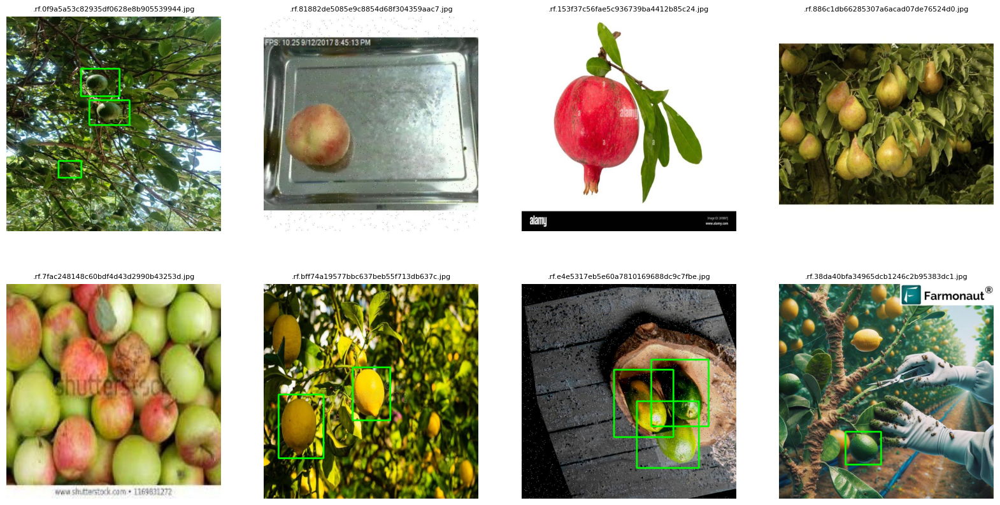

In [ ]:
# --------
# Función que dibuja las etiquetas del dataset sobre una imagen.
#   - Recibe: img, ruta de la imagen (su .txt está en la carpeta "labels" hermana de "images").
#   - Devuelve: la imagen en RGB con las cajas dibujadas en verde.
# --------
def dibujar_etiquetas(img):
    # Leemos la imagen (OpenCV la devuelve en BGR) y la convertimos a RGB para Matplotlib.
    im = cv2.cvtColor(cv2.imread(str(img)), cv2.COLOR_BGR2RGB)
    # Tomamos el alto y el ancho en píxeles.
    h, w = im.shape[:2]
    for linea in (img.parent.parent / "labels" / (img.stem + ".txt")).read_text().splitlines():
        # Desnormalizamos: de fracciones (0 a 1) a píxeles, y pasamos de centro a esquina superior izquierda.
        _, cx, cy, bw, bh = map(float, linea.split())
        x0, y0 = int((cx - bw / 2) * w), int((cy - bh / 2) * h)
        cv2.rectangle(im, (x0, y0), (x0 + int(bw * w), y0 + int(bh * h)), (0, 255, 0), max(2, w // 200))
    return im


# Mostramos 8 imágenes de entrenamiento al azar (cambiar la semilla para ver otras).
muestras = random.Random(1).sample(sorted((DATOS / "train" / "images").iterdir()), 8)
fig, ejes = plt.subplots(2, 4, figsize=(20, 10))
for ax, img in zip(ejes.flat, muestras):
    ax.imshow(dibujar_etiquetas(img)); ax.set_title(img.name[-40:], fontsize=8); ax.axis("off")
plt.show()

## **5. Preparación del modelo YOLO**

**¿Por qué YOLO?** *You Only Look Once* es una familia de redes de **detección de objetos** que, en una sola
pasada, entrega para cada objeto una caja, una clase y una confianza. Es rápida, lo que permite correrla en la
Raspberry Pi 5 del robot.

Alcanza con **detección** (cajas): lo que interesa es el centro del limón, y la profundidad la da el estéreo.

Se parte de **YOLO26n** preentrenado en COCO (*transfer learning*): la red ya sabe reconocer bordes, texturas y
formas, y solo se ajusta a la clase nueva. La `n` (*nano*) es la versión más liviana; es la misma que ya corre en
la Pi.

In [ ]:
# Cargamos la arquitectura YOLO26n con pesos preentrenados en COCO (80 clases de objetos comunes).
# Si el archivo .pt no existe, ultralytics lo descarga automáticamente.
modelo = YOLO("yolo26n.pt")

## **6. Entrenamiento del modelo**

Parámetros principales:

- `epochs`: cantidad de pasadas completas por el dataset.
- `patience`: corta el entrenamiento si la métrica de validación no mejora en esa cantidad de épocas.
- `imgsz`: resolución a la que se redimensionan las imágenes. **480**, la misma con la que predice la Pi; además
  entrena casi el doble de rápido que a 640.
- `cache="disk"`: la primera época guarda cada imagen ya achicada en el disco de Colab; las siguientes no
  vuelven a abrir los JPG grandes (la CPU de Colab, de 2 núcleos, es la que frena el entrenamiento).
- `batch`: imágenes por lote; si aparece un error de memoria, bajarlo a 8.
- `hsv_h`: cuánto se varía al azar el **tono** de las imágenes. Más alto que el de fábrica (0.015): las cámaras
  NoIR corren el color, sobre todo el verde, y así el modelo depende menos del tono exacto.

Los resultados se guardan en Drive. Si Colab se desconecta, correr la celda de *Continuar* que está abajo.

In [ ]:
# Entrenamos el modelo. En cada época, train recorre todas las imágenes de entrenamiento,
# ajusta los pesos y luego evalúa con las de validación. En pantalla se ve, por época,
# la pérdida de cajas (box_loss), la de clasificación (cls_loss) y las métricas P, R y mAP.
modelo.train(
    data=str(DATOS / "data.yaml"),   # archivo .yaml del dataset unificado
    epochs=100,                      # número de épocas
    patience=20,                     # parada temprana: corta si 20 épocas seguidas no mejoran
    imgsz=480,                       # las imágenes se redimensionan a 480 x 480 (como en la Pi)
    cache="disk",                    # guarda las imágenes achicadas: épocas más rápidas
    batch=16,                        # imágenes por lote (bajar a 8 si falta memoria de GPU)
    hsv_h=0.05,                      # variación de tono (las NoIR corren el color)
    project=str(SALIDA),             # carpeta de resultados (en Drive)
    name="entreno",                  # subcarpeta: SALIDA/entreno
    exist_ok=True,                   # reutilizar esa carpeta si ya existe
)

New https://pypi.org/project/ultralytics/8.4.191 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.153 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=disk, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datos/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.05, hsv_s=0.7, hsv_v=0.4, imgsz=480, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, mo

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x798778370b40>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

In [ ]:
# Continuar un entrenamiento cortado (solo si hace falta): sacar el "#" y correr.
# YOLO(str(SALIDA / "entreno/weights/last.pt")).train(resume=True)

### **6.1 Curvas de entrenamiento**

Las pérdidas (*loss*) de entrenamiento y validación deben bajar; las métricas (precisión, recobrado, mAP) deben
subir. Si la pérdida de validación sube mientras la de entrenamiento baja, el modelo está **sobreajustando**
(memoriza en lugar de generalizar).

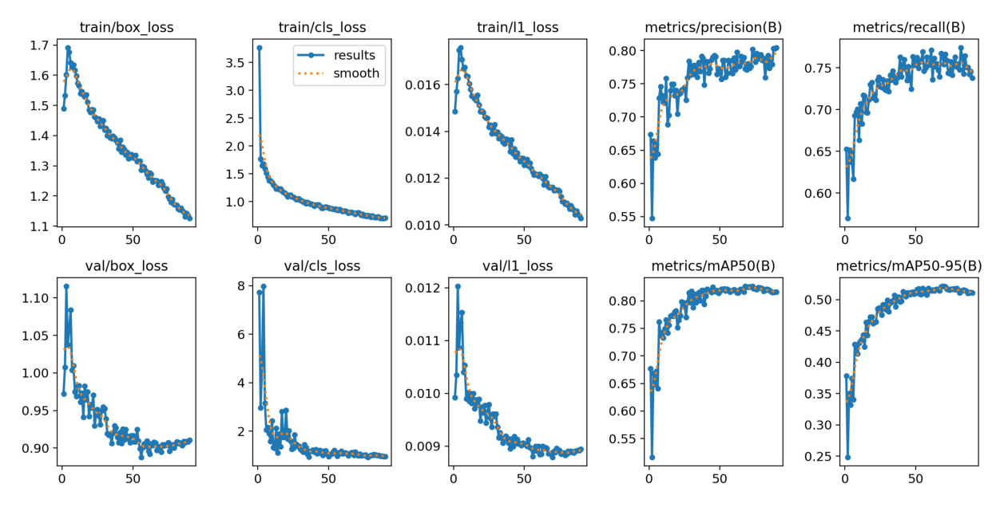

In [ ]:
# Mostramos results.png, que ultralytics genera con todas las curvas (pérdidas y métricas por época).
img = cv2.cvtColor(cv2.imread(str(SALIDA / "entreno/results.png")), cv2.COLOR_BGR2RGB)
plt.figure(figsize=(16, 8))
plt.imshow(img)
plt.axis("off")
plt.show()

## **7. Evaluación del modelo**

- **Precisión (P)**: de lo que el modelo dijo que era limón, ¿qué fracción realmente lo era? Una precisión baja
  significa que el brazo iría a buscar hojas o frutas que no son limones.
- **Recobrado (R)**: de todos los limones que había, ¿qué fracción encontró? Un recobrado bajo significa limones
  que quedan sin cosechar.
- **mAP50**: precisión media considerando correcta una caja que se superpone al menos 50 % con la real.

El requisito **B4** del TPF pide **P ≥ 0,80 y R ≥ 0,80**. La celda compara contra ese umbral.
**Ojo:** el TPF lo mide sobre 30 frutos del montaje real, no sobre este dataset. Además, acá el conjunto de prueba
sale de las mismas fuentes que el de entrenamiento, así que estos números son **optimistas**.

In [ ]:
# Cargamos el mejor modelo (mayor mAP en validación) y lo evaluamos en test (o en val si no hay test).
mejor = YOLO(str(SALIDA / "entreno/weights/best.pt"))
parte_eval = "test" if "test" in partes else "val"
m = mejor.val(data=str(DATOS / "data.yaml"), split=parte_eval, imgsz=480)

# Mostramos las métricas y las comparamos con el criterio B4.
print(f"{parte_eval}: precisión {m.box.mp:.3f}  recobrado {m.box.mr:.3f}  mAP50 {m.box.map50:.3f}  "
      f"mAP50-95 {m.box.map:.3f}")
print("Criterio B4 (P y R >= 0.80):", "CUMPLE" if (m.box.mp >= 0.8 and m.box.mr >= 0.8) else "NO CUMPLE")

Ultralytics 8.4.153 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 120 layers, 2,375,031 parameters, 0 gradients, 5.3 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 33.6±17.6 MB/s, size: 63.9 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/datos/test/labels... 335 images, 200 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 335/335 711.5it/s 0.5s
val: New cache created: /content/datos/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 21/21 5.5it/s 3.9s
                   all        335        274      0.894      0.832      0.919      0.709
Speed: 1.7ms preprocess, 3.7ms inference, 0.0ms loss, 1.4ms postprocess per image
Results saved to /content/runs/detect/val
test: precisión 0.894  recobrado 0.832  mAP50 0.919  mAP50-95 0.709
Criteri

### **7.1 Matriz de confusión**

Con una sola clase, la matriz muestra cuántos limones se detectaron, cuántos se escaparon (fila `background`:
falsos negativos) y cuántas detecciones fueron de algo que no era limón (columna `background`: falsos positivos).

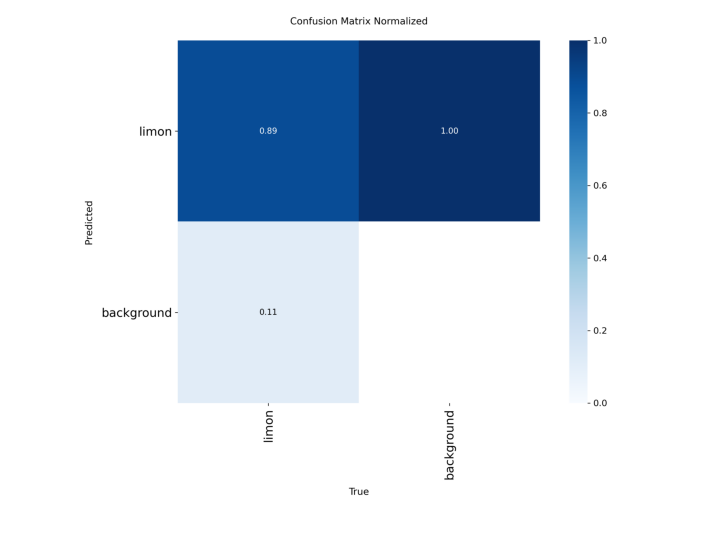

In [ ]:
# Mostramos la matriz de confusión normalizada, que la evaluación guarda como imagen en su carpeta.
img = cv2.cvtColor(cv2.imread(str(Path(m.save_dir) / "confusion_matrix_normalized.png")), cv2.COLOR_BGR2RGB)
plt.figure(figsize=(9, 9))
plt.imshow(img)
plt.axis("off")
plt.show()

## **8. Inferencia sobre imágenes de prueba**

Se eligen imágenes al azar que el modelo **no vio al entrenar** y se comparan lado a lado las etiquetas reales y
lo que detecta el modelo. Se predice a **480**, el mismo tamaño que usa la Pi. `CONF_MIN` es la confianza mínima
para aceptar una detección: subirla reduce falsos positivos a costa de perder limones.

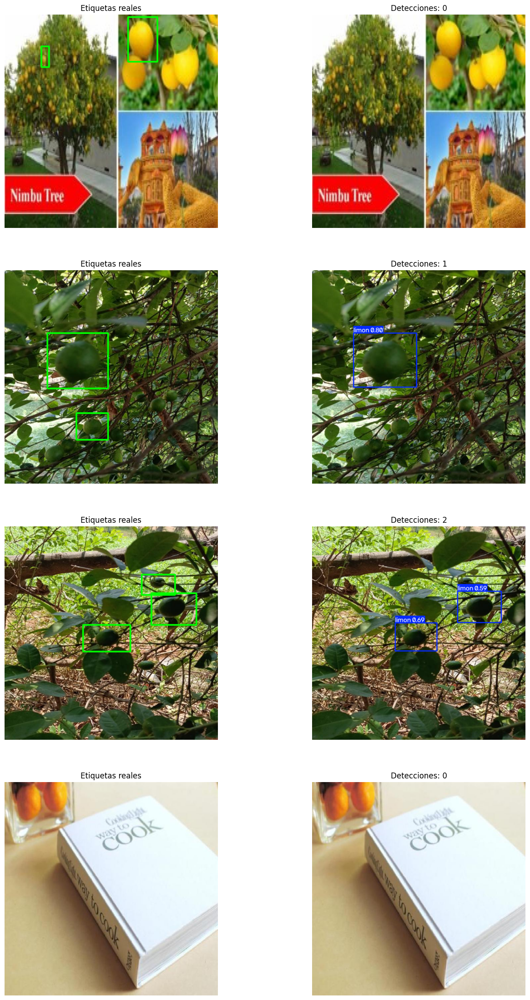

In [ ]:
# Confianza mínima para aceptar una detección (de 0 a 1).
CONF_MIN = 0.40

# Elegimos 4 imágenes de prueba al azar (cambiar la semilla para ver otras).
fotos = random.Random(2).sample(sorted((DATOS / parte_eval / "images").iterdir()), 4)
resultados = mejor.predict([str(f) for f in fotos], imgsz=480, conf=CONF_MIN, verbose=False)

# Una fila por imagen: a la izquierda las etiquetas (la "verdad"), a la derecha lo que detectó el modelo
# (r.plot() devuelve la imagen con las cajas, en BGR).
fig, ejes = plt.subplots(4, 2, figsize=(16, 28))
for (ax_real, ax_pred), f, r in zip(ejes, fotos, resultados):
    ax_real.imshow(dibujar_etiquetas(f)); ax_real.set_title("Etiquetas reales"); ax_real.axis("off")
    ax_pred.imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB))
    ax_pred.set_title(f"Detecciones: {len(r.boxes)}"); ax_pred.axis("off")
plt.show()

## **9. Exportar el modelo para el robot**

En la Raspberry Pi conviene no usar PyTorch directamente. Se exporta a **NCNN** (optimizado para CPU ARM), a
**480**: el tamaño con el que predice el nodo `yolo_ros` de la Pi. El modelo exportado se carga igual:
`YOLO("limon_yolo26n_ncnn_model")`. Todo queda en Drive.

In [ ]:
# Versión del modelo: va en el nombre de los archivos para no pisar los anteriores.
VERSION = "v2"
# Copiamos best.pt a Drive con un nombre claro.
shutil.copy(SALIDA / "entreno/weights/best.pt", SALIDA / f"limon_yolo26n_{VERSION}.pt")
# Exportamos a NCNN (la primera vez, ultralytics instala el paquete ncnn) y copiamos la carpeta a Drive.
ruta_ncnn = Path(mejor.export(format="ncnn", imgsz=480))
destino = SALIDA / f"limon_yolo26n_{VERSION}_ncnn_model"
shutil.rmtree(destino, ignore_errors=True)
shutil.copytree(ruta_ncnn, destino)
print("Listo en Drive:")
for f in sorted(SALIDA.iterdir()):
    print("  ", f.name)

Ultralytics 8.4.153 🚀 Python-3.13.16 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
YOLO26n summary (fused): 120 layers, 2,375,031 parameters, 0 gradients, 3.0 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/arturito/limon_yolo/entreno/weights/best.pt' with input shape (1, 3, 480, 480) BCHW and output shape(s) (1, 5, 4725) (5.1 MB)

NCNN: starting export with NCNN 1.0.20261020 and PNNX 20260526...
NCNN: export success ✅ 4.8s, saved as '/content/drive/MyDrive/arturito/limon_yolo/entreno/weights/best_ncnn_model' (9.2 MB)

Export complete (5.2s)
Results saved to /content/drive/MyDrive/arturito/limon_yolo/entreno/weights/best_ncnn_model
Predict:         yolo predict task=detect model=/content/drive/MyDrive/arturito/limon_yolo/entreno/weights/best_ncnn_model imgsz=480 
Validate:        yolo val task=detect model=/content/drive/MyDrive/arturito/limon_yolo/entreno/weights/best_ncnn_model imgsz=480 data=/content/datos/data.yaml  
Visualize:       https://netron.app
Listo en Drive:
  

## **10. Probar con una imagen propia**

Subir una foto de limones (por ejemplo, del limonero del lab o sacada con las cámaras NoIR del robot) y ver qué
detecta el modelo. Lo esperable es que funcione peor que en el dataset si el fondo, la iluminación o la cámara son
distintos: eso indica que hay que **sumar imágenes propias etiquetadas** y reentrenar. Probar en especial
limones **verdes en el árbol, entre hojas**.

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Saving limon6.jpeg to limon6.jpeg
Saving limon5.jpeg to limon5.jpeg
Saving limon4.jpeg to limon4.jpeg
Saving limon3.jpeg to limon3 (1).jpeg
Saving limon2.jpeg to limon2 (1).jpeg
Saving limon1.jpeg to limon1 (2).jpeg


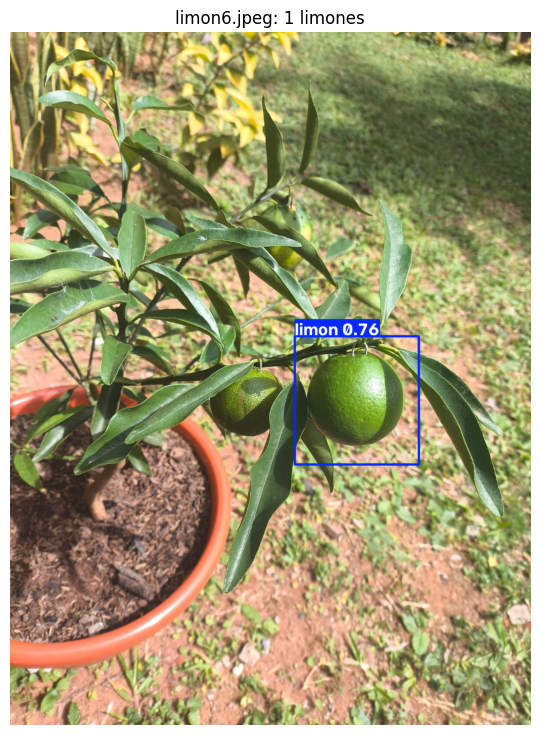

Confianzas: [0.76]


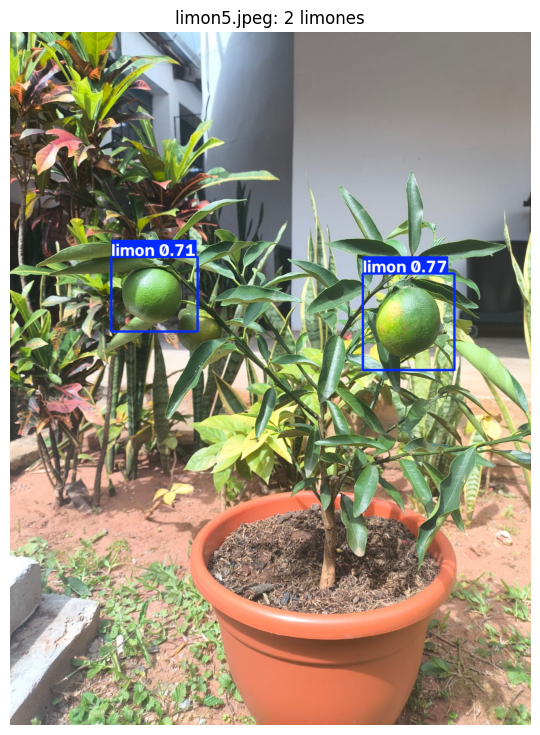

Confianzas: [0.77, 0.71]


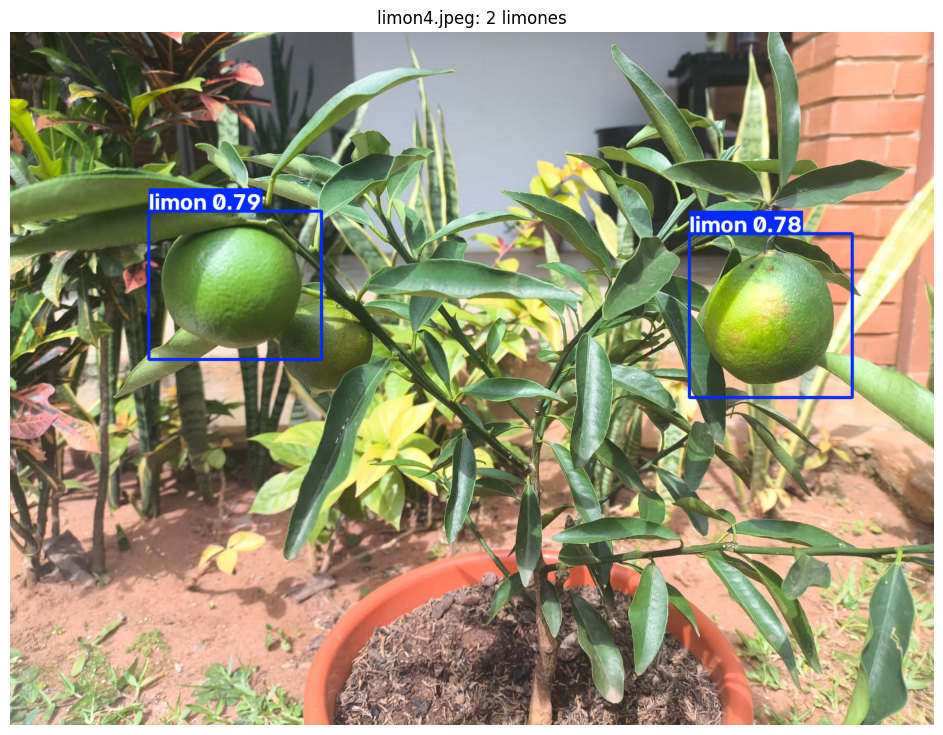

Confianzas: [0.79, 0.78]


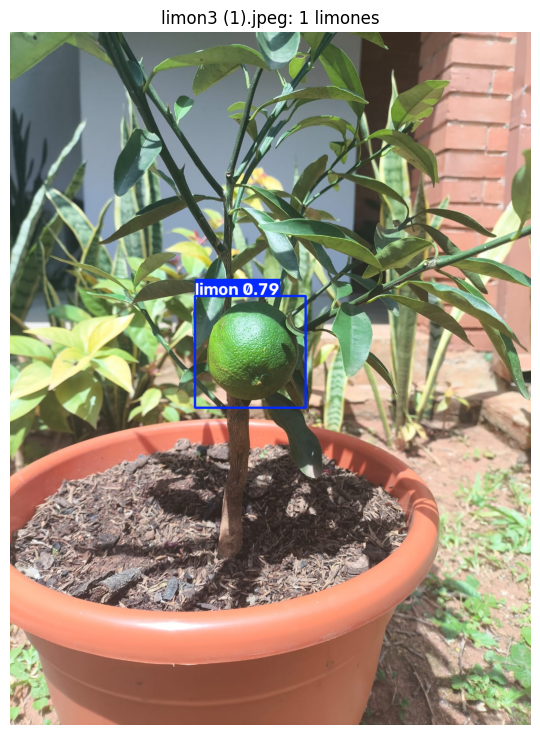

Confianzas: [0.79]


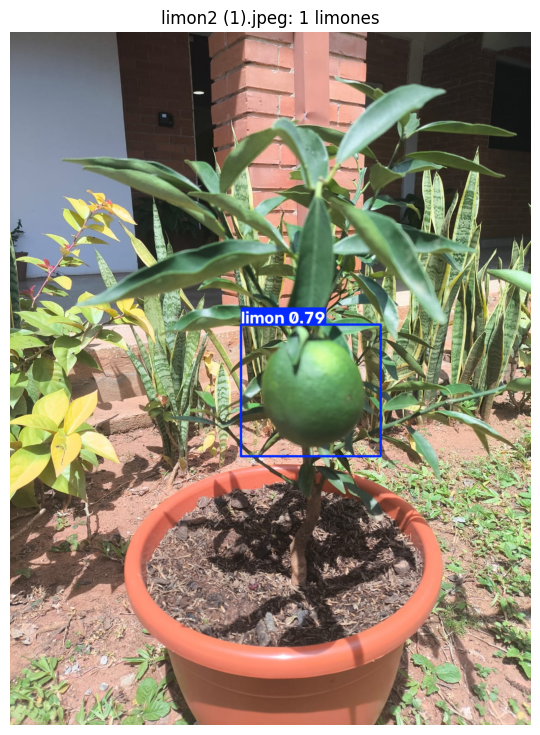

Confianzas: [0.79]


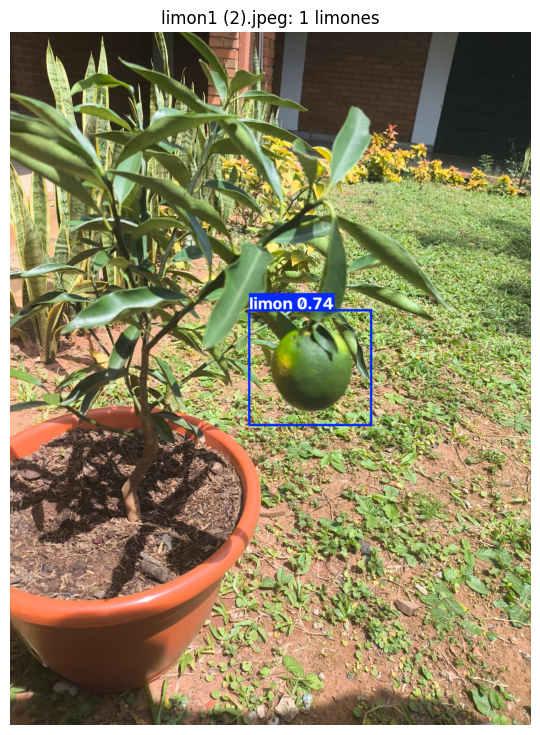

Confianzas: [0.74]


In [7]:
!pip install -q ultralytics
from ultralytics import YOLO
from google.colab import drive, files
import cv2, matplotlib.pyplot as plt

drive.mount("/content/drive")
mejor = YOLO("/content/drive/MyDrive/arturito_v2/limon_yolo_v2/limon_yolo26n_v2.pt")
CONF_MIN = 0.40

for nombre in files.upload():
    r = mejor.predict(nombre, imgsz=480, conf=CONF_MIN, verbose=False)[0]
    plt.figure(figsize=(12, 9))
    plt.imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB))
    plt.title(f"{nombre}: {len(r.boxes)} limones"); plt.axis("off"); plt.show()
    print("Confianzas:", [round(c, 2) for c in r.boxes.conf.tolist()])



## **11. De la detección a las coordenadas del limón**

YOLO entrega cajas en **píxeles**; el brazo necesita una posición en **metros**. Con una sola cámara la distancia
$Z$ solo se puede estimar suponiendo el tamaño del fruto, y el error relativo en $Z$ es igual al error relativo en
ese tamaño supuesto ($\Delta Z / Z = \Delta D / D$): con limones de tamaños muy distintos, eso no cumple B5.

Por eso Arturito usa **visión estereoscópica** (repo `HecVelaz/vision_estereo`, en la Pi): las dos cámaras miden
la **disparidad** $d$ de cada píxel y la profundidad sale por triangulación, sin suponer el tamaño del limón:

$$Z = \frac{f_x \, B}{d}$$

con $B$ el baseline (89,5 mm, calibrado). El nodo `localizador_node` toma el centro de la caja de YOLO, lee la
disparidad alrededor y publica `/limon/posicion` (`geometry_msgs/PointStamped`) en el marco de la cámara
izquierda; `tf2` lo lleva a la base del brazo.

Con un limón real en el lab dio un **error 3D máximo de 17 mm** a 0,4-0,9 m (B5 pide ≤ 35 mm). Falta repetirlo al
aire libre.

## **12. Qué falta**

1. **Fotos propias con las NoIR:** limones del montaje real (verdes, amarillos y **anaranjados**, que ningún
   dataset trae), al sol y con la cámara del robot. Etiquetarlas en Roboflow y sumarlas a `DATASETS`.
2. **Clases de B3** (cosechable / no cosechable / obstáculo): hoy hay una sola clase, `limon`. Se pueden agregar
   cuando las fotos propias muestren que las NoIR distinguen la madurez.
3. **Validación con 30 limones (B4 y B5):** con el modelo en la Pi, medir con regla la posición real de cada
   limón y comparar con `/limon/posicion`.
4. **Usarlo en la Pi:** bajar de Drive la carpeta `limon_yolo26n_ncnn_model` y copiarla a la Pi:

```bash
scp -r limon_yolo26n_ncnn_model r2d2@100.116.96.71:~/vision_estereo/modelos/
```

El modelo que está hoy en la Pi (`~/vision_estereo/modelos/limon_yolo26n_ncnn_model`, del 28/09) queda
reemplazado: conviene renombrar el viejo antes de copiar, para poder volver atrás.